<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>SQL Window Functions Assignment<br></h3></center>

# Introduction
This notebook contains the complete execution and analysis of the **SQL Window Functions Assignment**. 

Using an in-memory SQLite database, we create the required schema, insert test records across categories (`Agni`, `Dharti`, `Vayu`), and execute the three core categories of window functions:
1. **Aggregate Window Functions**: Cumulative sums, moving averages, and running counts with `PARTITION BY` and `ORDER BY`.
2. **Ranking Window Functions**: Comparing `ROW_NUMBER()`, `RANK()`, `DENSE_RANK()`, and `PERCENT_RANK()` to understand tie-breaking and rank gaps.
3. **Analytic / Value Window Functions**: Inspecting `FIRST_VALUE()`, `LAST_VALUE()`, `LEAD()`, and `LAG()`, including the impact of SQL default window frames.


In [1]:
# 1. Imports and Database Connection
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visualization style
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 4.5)

# Connect to in-memory SQLite database
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

print("Connected to SQLite database successfully!")


Connected to SQLite database successfully!


---
## 1. Schema Creation & Data Population

Creating table `test_data` and inserting the 7 assignment rows.


In [2]:
# DDL: Create Table
cursor.execute('''
CREATE TABLE test_data (
    new_id INT,
    new_cat VARCHAR(255)
);
''')

# DML: Insert Data
cursor.execute('''
INSERT INTO test_data (new_id, new_cat)
VALUES
    (100, 'Agni'),(200, 'Agni'),
    (500, 'Dharti'),(700, 'Dharti'),
    (200, 'Vayu'),(300, 'Vayu'),
    (500, 'Vayu');
''')
conn.commit()

# Display inserted table
df_raw = pd.read_sql_query("SELECT * FROM test_data;", conn)
print("Table: test_data")
df_raw


Table: test_data


,new_id,new_cat
0,100,Agni
1,200,Agni
2,500,Dharti
3,700,Dharti
4,200,Vayu
5,300,Vayu
6,500,Vayu


---
## 2. Aggregate Window Functions

Running cumulative metrics within each category partition:
```sql
SELECT new_id, new_cat,
SUM(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Total",
AVG(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Average",
COUNT(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Count",  
MIN(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Min",
MAX(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Max"
FROM test_data;
```


In [3]:
# Execute Aggregate Window Functions Query
query_agg = '''
SELECT new_id, new_cat,
    SUM(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Total",
    AVG(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Average",
    COUNT(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Count",  
    MIN(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Min",
    MAX(new_id) OVER( PARTITION BY new_cat ORDER BY new_id ) AS "Max"
FROM test_data;
'''

df_agg = pd.read_sql_query(query_agg, conn)
print("Aggregate Window Functions Output:")
df_agg


Aggregate Window Functions Output:


,new_id,new_cat,Total,Average,Count,Min,Max
0,100,Agni,100,100.000000,1,100,100
1,200,Agni,300,150.000000,2,100,200
2,500,Dharti,500,500.000000,1,500,500
3,700,Dharti,1200,600.000000,2,500,700
4,200,Vayu,200,200.000000,1,200,200
5,300,Vayu,500,250.000000,2,200,300
6,500,Vayu,1000,333.333333,3,200,500


### Key Takeaways from Aggregate Output:
- **`PARTITION BY new_cat`**: Resets the calculation for each distinct category (`Agni`, `Dharti`, `Vayu`).
- **`ORDER BY new_id`**: Makes the aggregation cumulative (running totals and moving averages):
  - In `Agni`: Total starts at 100, then adds 200 to become 300.
  - In `Dharti`: Total starts at 500, then adds 700 to reach 1200.
  - In `Vayu`: Total accumulates across three rows: 200 $ightarrow$ 500 $ightarrow$ 1000.


---
## 3. Ranking Window Functions

Evaluating how different ranking functions handle ties (`new_id = 200` and `new_id = 500`):
```sql
SELECT new_id,
ROW_NUMBER() OVER(ORDER BY new_id) AS "ROW_NUMBER",
RANK() OVER(ORDER BY new_id) AS "RANK",
DENSE_RANK() OVER(ORDER BY new_id) AS "DENSE_RANK",  
PERCENT_RANK() OVER(ORDER BY new_id) AS "PERCENT_RANK"
FROM test_data;
```


In [4]:
# Execute Ranking Window Functions Query
query_rank = '''
SELECT new_id,
    ROW_NUMBER() OVER(ORDER BY new_id) AS "ROW_NUMBER",
    RANK() OVER(ORDER BY new_id) AS "RANK",
    DENSE_RANK() OVER(ORDER BY new_id) AS "DENSE_RANK",  
    PERCENT_RANK() OVER(ORDER BY new_id) AS "PERCENT_RANK"
FROM test_data;
'''

df_rank = pd.read_sql_query(query_rank, conn)
print("Ranking Window Functions Output:")
df_rank


Ranking Window Functions Output:


,new_id,ROW_NUMBER,RANK,DENSE_RANK,PERCENT_RANK
0,100,1,1,1,0.000000
1,200,2,2,2,0.166667
2,200,3,2,2,0.166667
3,300,4,4,3,0.500000
4,500,5,5,4,0.666667
5,500,6,5,4,0.666667
6,700,7,7,5,1.000000


### Practical Differences Between Ranking Functions:
1. **`ROW_NUMBER()`**: Generates a strictly unique sequential integer ($1, 2, 3, 4, 5, 6, 7$) without duplicates, even when `new_id` has identical values (e.g., the two `200`s receive ranks 2 and 3).
2. **`RANK()`**: Assigns equal rank to tied values, but **skips subsequent positions** ($1, 2, 2, 4, 5, 5, 7$). Ranks 3 and 6 are skipped.
3. **`DENSE_RANK()`**: Assigns equal rank to tied values **without skipping any positions** ($1, 2, 2, 3, 4, 4, 5$).
4. **`PERCENT_RANK()`**: Computes the relative rank percentile as:
$$\text{PERCENT\_RANK} = \frac{\text{RANK} - 1}{\text{Total Rows} - 1} = \frac{\text{RANK} - 1}{6}$$


---
## 4. Analytic Window Functions

Executing row navigation and boundary functions:
```sql
SELECT new_id,
FIRST_VALUE(new_id) OVER( ORDER BY new_id) AS "FIRST_VALUE",
LAST_VALUE(new_id)  OVER( ORDER BY new_id) AS "LAST_VALUE",
LEAD(new_id)        OVER( ORDER BY new_id) AS "LEAD",  
LAG(new_id)         OVER( ORDER BY new_id) AS "LAG"
FROM test_data;
```


In [5]:
# Execute Analytic Window Functions Query
query_analytic = '''
SELECT new_id,
    FIRST_VALUE(new_id) OVER( ORDER BY new_id) AS "FIRST_VALUE",
    LAST_VALUE(new_id)  OVER( ORDER BY new_id) AS "LAST_VALUE",
    LEAD(new_id)        OVER( ORDER BY new_id) AS "LEAD",  
    LAG(new_id)         OVER( ORDER BY new_id) AS "LAG"
FROM test_data;
'''

df_analytic = pd.read_sql_query(query_analytic, conn)
print("Analytic Window Functions Output (Default Window Frame):")
df_analytic


Analytic Window Functions Output (Default Window Frame):


,new_id,FIRST_VALUE,LAST_VALUE,LEAD,LAG
0,100,100,100,200.0,NaN
1,200,100,200,200.0,100.0
2,200,100,200,300.0,200.0
3,300,100,300,500.0,200.0
4,500,100,500,500.0,300.0
5,500,100,500,700.0,500.0
6,700,100,700,NaN,500.0


### Important SQL Note on `LAST_VALUE()`:
- **`FIRST_VALUE(new_id)`**: Returns `100` (the first row) for all records.
- **`LEAD(new_id)`**: Pulls the next row's value. The final row is `None` (`NULL`).
- **`LAG(new_id)`**: Pulls the previous row's value. The first row is `None` (`NULL`).
- **Why does `LAST_VALUE` return the current row instead of 700?**
  In SQL, the default window frame with `ORDER BY` is:
  `RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`
  Because the window ends at the current row, `LAST_VALUE` only sees rows up to the current row.

To get the true last value (`700`) for all rows, expand the frame explicitly:


In [6]:
# Demonstrating Full Window Frame for LAST_VALUE
query_last_value_fix = '''
SELECT new_id,
    LAST_VALUE(new_id) OVER( ORDER BY new_id ) AS "LAST_VALUE_DEFAULT",
    LAST_VALUE(new_id) OVER( 
        ORDER BY new_id 
        ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING 
    ) AS "LAST_VALUE_FULL_FRAME"
FROM test_data;
'''

pd.read_sql_query(query_last_value_fix, conn)


,new_id,LAST_VALUE_DEFAULT,LAST_VALUE_FULL_FRAME
0,100,100,700
1,200,200,700
2,200,200,700
3,300,300,700
4,500,500,700
5,500,500,700
6,700,700,700


---
## 5. Visual Analysis of Window Operations


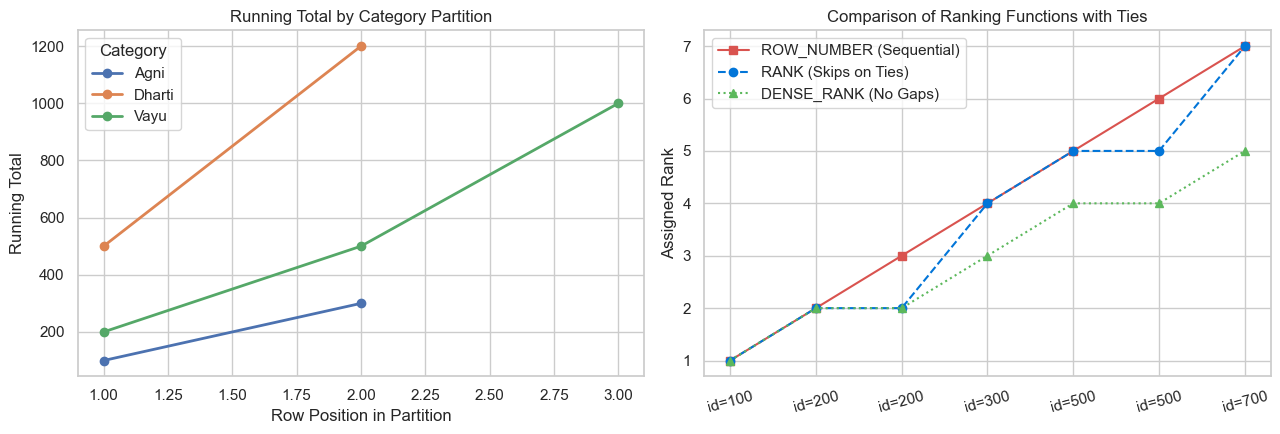

In [7]:
# Plot 1: Cumulative Totals by Partition
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot running sums per category
for cat in df_agg['new_cat'].unique():
    subset = df_agg[df_agg['new_cat'] == cat]
    axes[0].plot(range(1, len(subset) + 1), subset['Total'], marker='o', linewidth=2, label=cat)

axes[0].set_title('Running Total by Category Partition')
axes[0].set_xlabel('Row Position in Partition')
axes[0].set_ylabel('Running Total')
axes[0].legend(title='Category')

# Plot 2: Ranking comparison (Ties handling)
x = np.arange(len(df_rank))
axes[1].plot(x, df_rank['ROW_NUMBER'], marker='s', label='ROW_NUMBER (Sequential)', color='#d9534f')
axes[1].plot(x, df_rank['RANK'], marker='o', label='RANK (Skips on Ties)', color='#0275d8', linestyle='--')
axes[1].plot(x, df_rank['DENSE_RANK'], marker='^', label='DENSE_RANK (No Gaps)', color='#5cb85c', linestyle=':')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"id={v}" for v in df_rank['new_id']], rotation=15)
axes[1].set_title('Comparison of Ranking Functions with Ties')
axes[1].set_ylabel('Assigned Rank')
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 6. Summary Comparison


In [8]:
# Final Comparison Table of Window Operations
summary_table = pd.DataFrame({
    'Row': range(1, len(df_raw) + 1),
    'new_id': df_rank['new_id'],
    'ROW_NUMBER': df_rank['ROW_NUMBER'],
    'RANK': df_rank['RANK'],
    'DENSE_RANK': df_rank['DENSE_RANK'],
    'PERCENT_RANK': df_rank['PERCENT_RANK'].round(4),
    'LEAD': df_analytic['LEAD'].fillna('NULL'),
    'LAG': df_analytic['LAG'].fillna('NULL')
})

print("Window Functions Quick Reference Table:")
summary_table


Window Functions Quick Reference Table:


,Row,new_id,ROW_NUMBER,RANK,DENSE_RANK,PERCENT_RANK,LEAD,LAG
0,1,100,1,1,1,0.0000,200.0,NULL
1,2,200,2,2,2,0.1667,200.0,100.0
2,3,200,3,2,2,0.1667,300.0,200.0
3,4,300,4,4,3,0.5000,500.0,200.0
4,5,500,5,5,4,0.6667,500.0,300.0
5,6,500,6,5,4,0.6667,700.0,500.0
6,7,700,7,7,5,1.0000,NULL,500.0
